In [8]:
# Llama-3.2 is gated. Store a Kaggle secret named HF_TOKEN.
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

try:
    token = UserSecretsClient().get_secret('HF_TOKEN')
    login(token=token)
    print('Hugging Face login: OK')
except Exception as exc:
    print('HF login was not completed automatically:', exc)
    print('If the model is already cached and accessible, you can continue.')


Hugging Face login: OK


In [9]:
import torch
from transformers import AutoModelForCausalLM
import matplotlib.pyplot as plt

model = AutoModelForCausalLM.from_pretrained('meta-llama/Llama-3.2-1B',)

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]


Question 4: SVD Analysis on q_proj Weights (Layers 0, 7, 15)


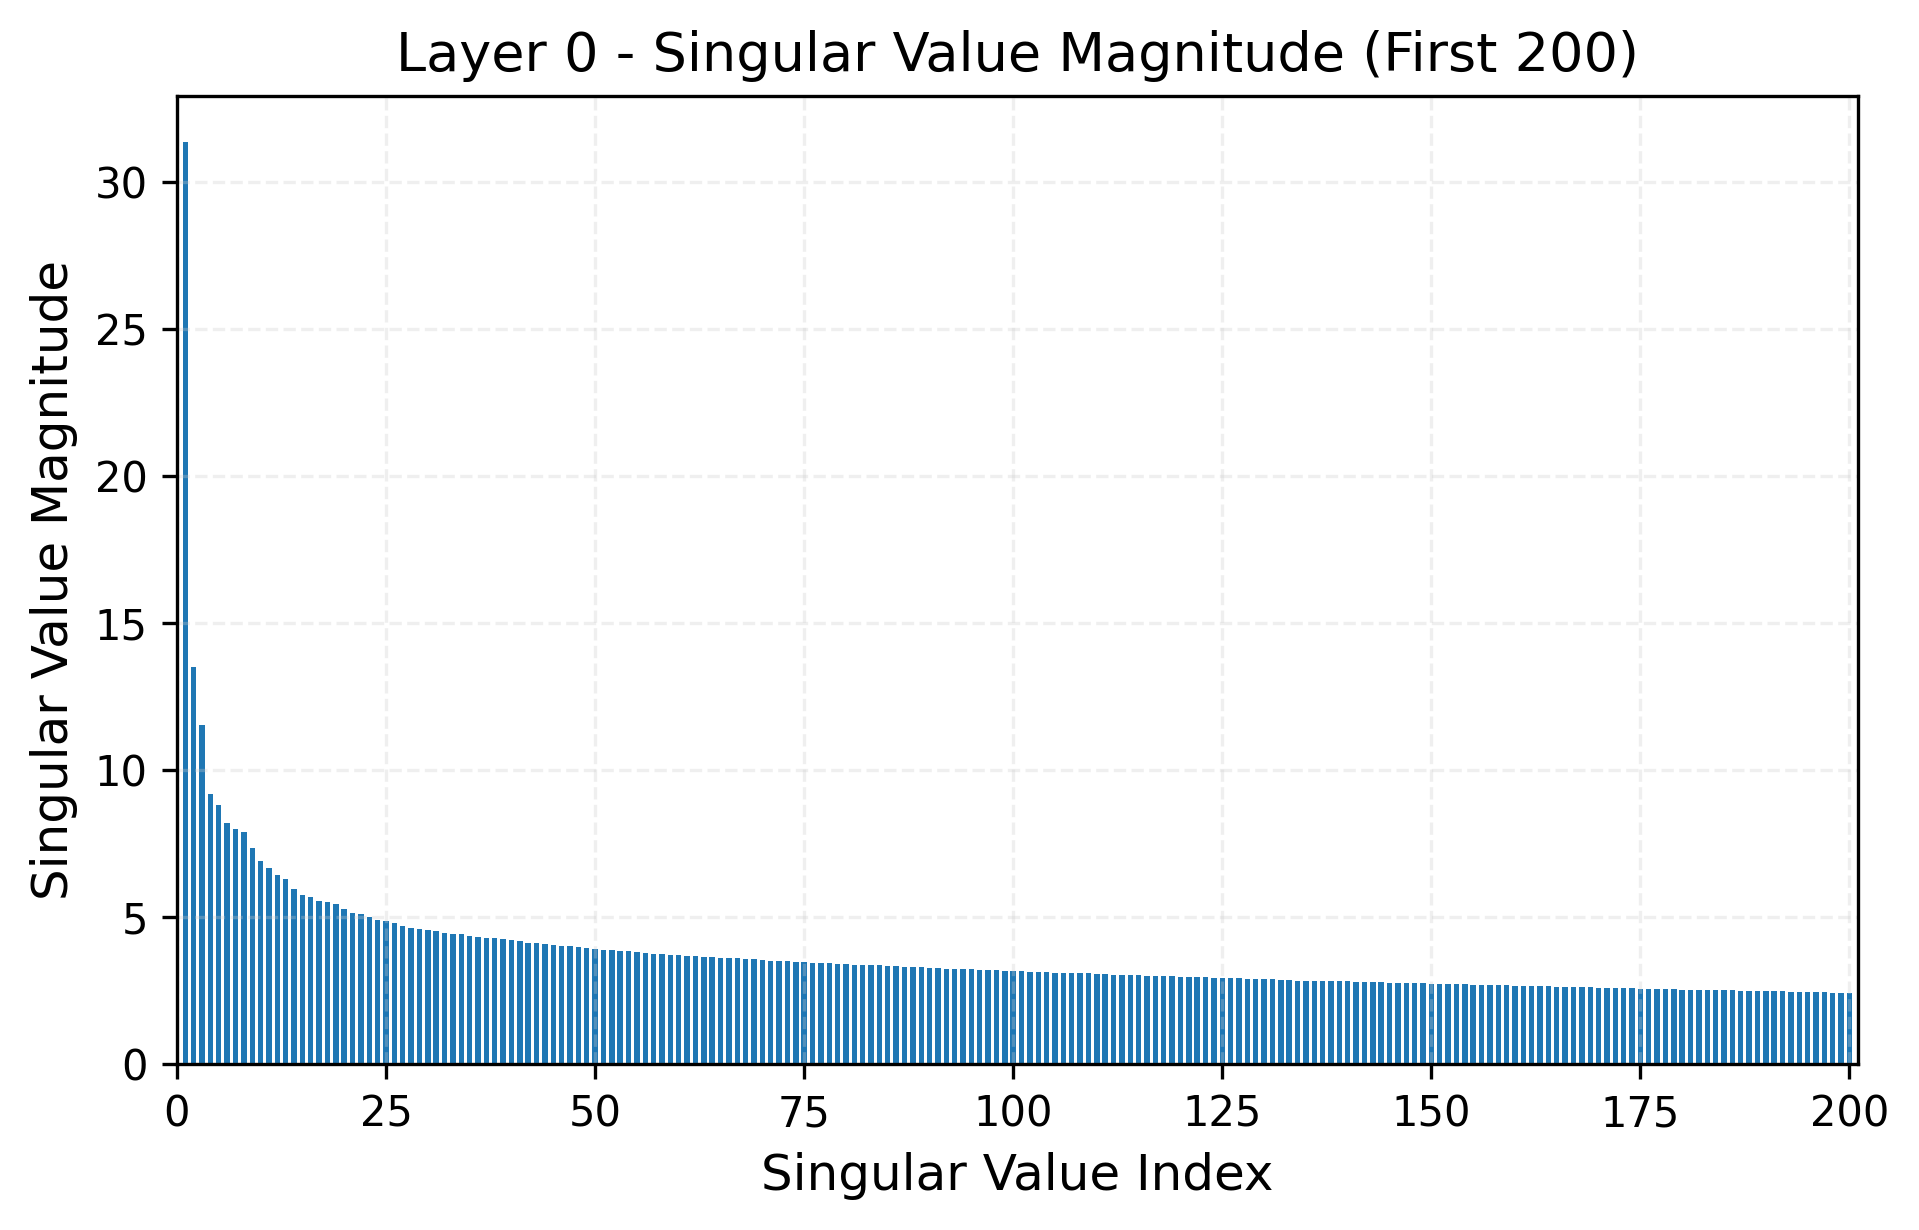

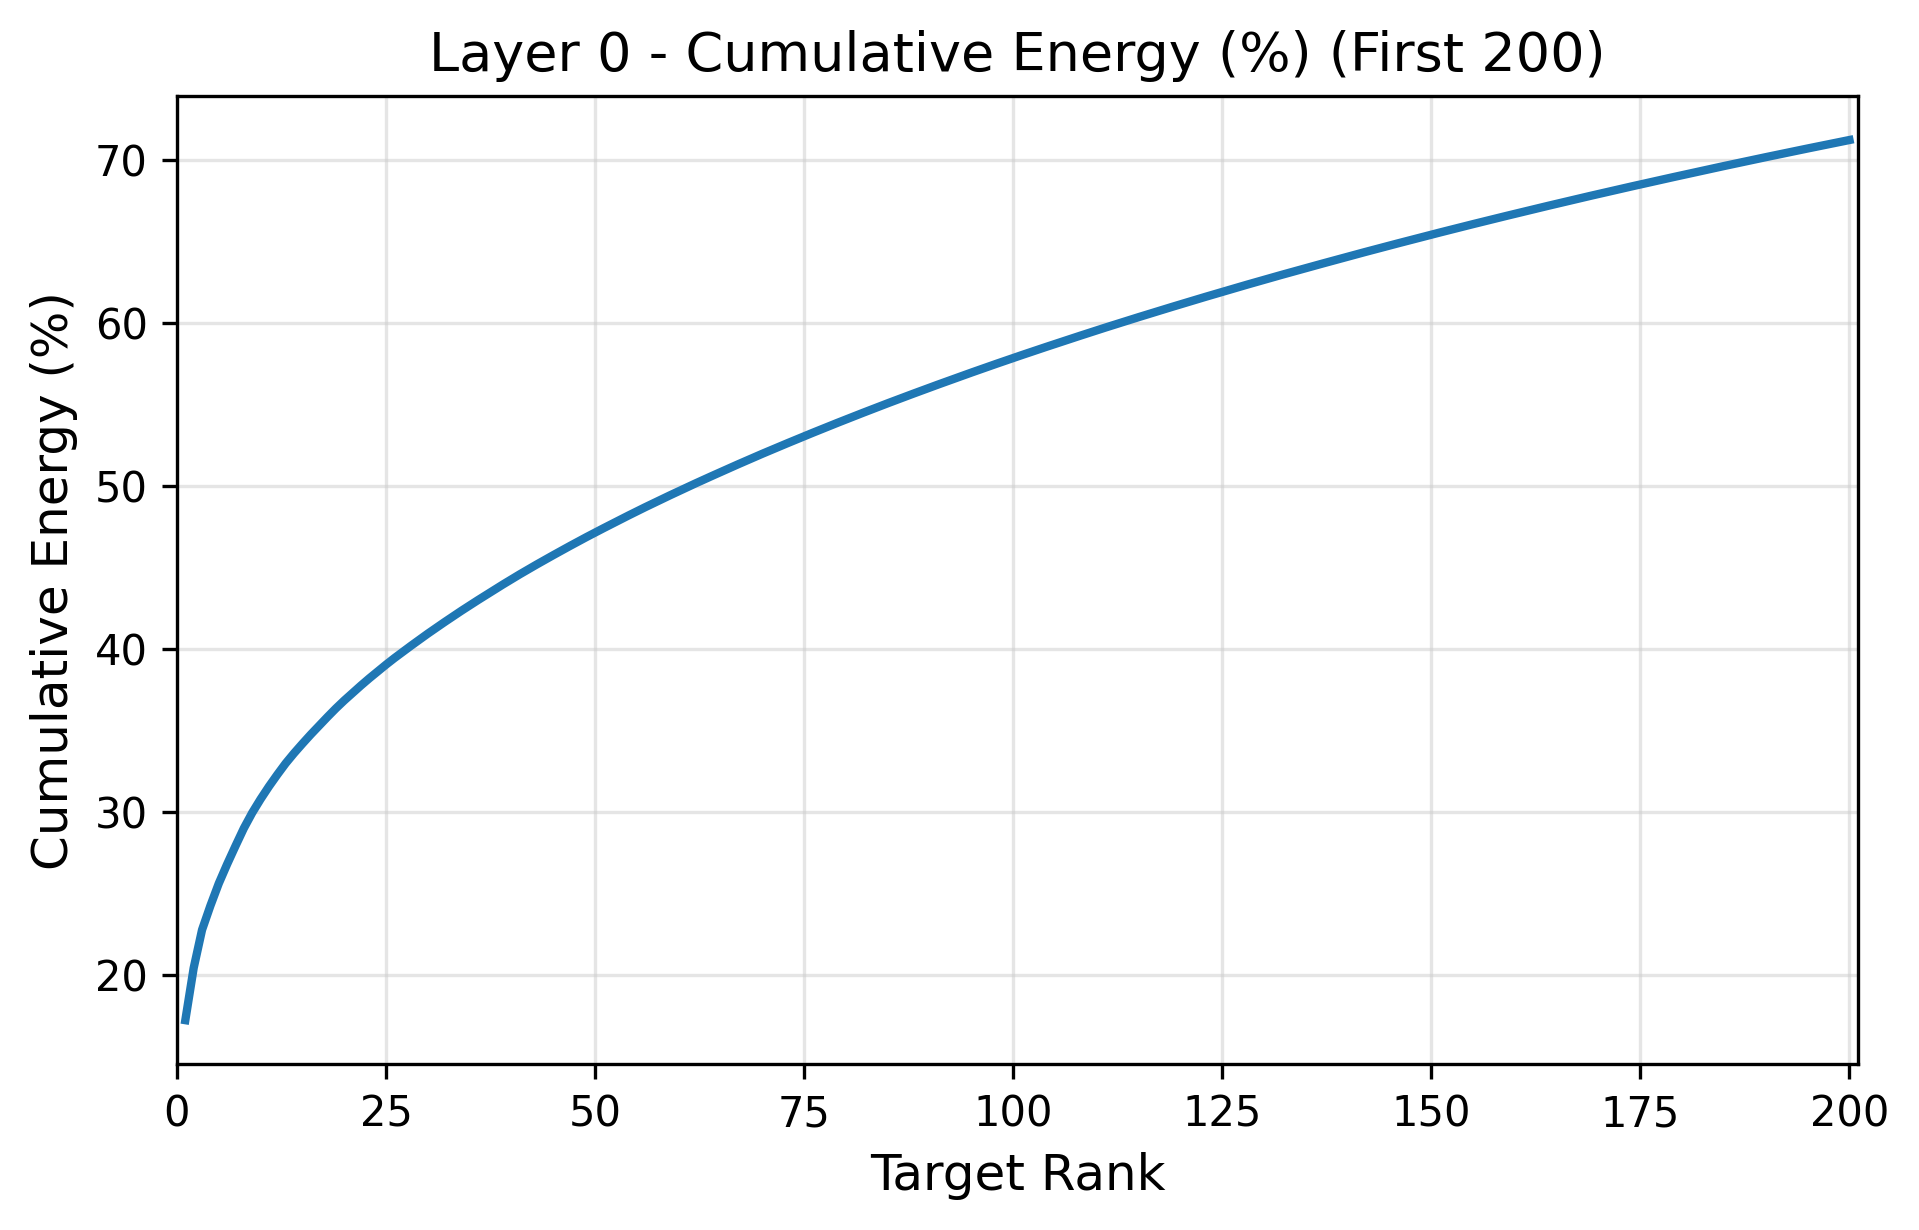

✅ Layer 0: 達到 50% 能量所需的 Minimum Target Rank = 62


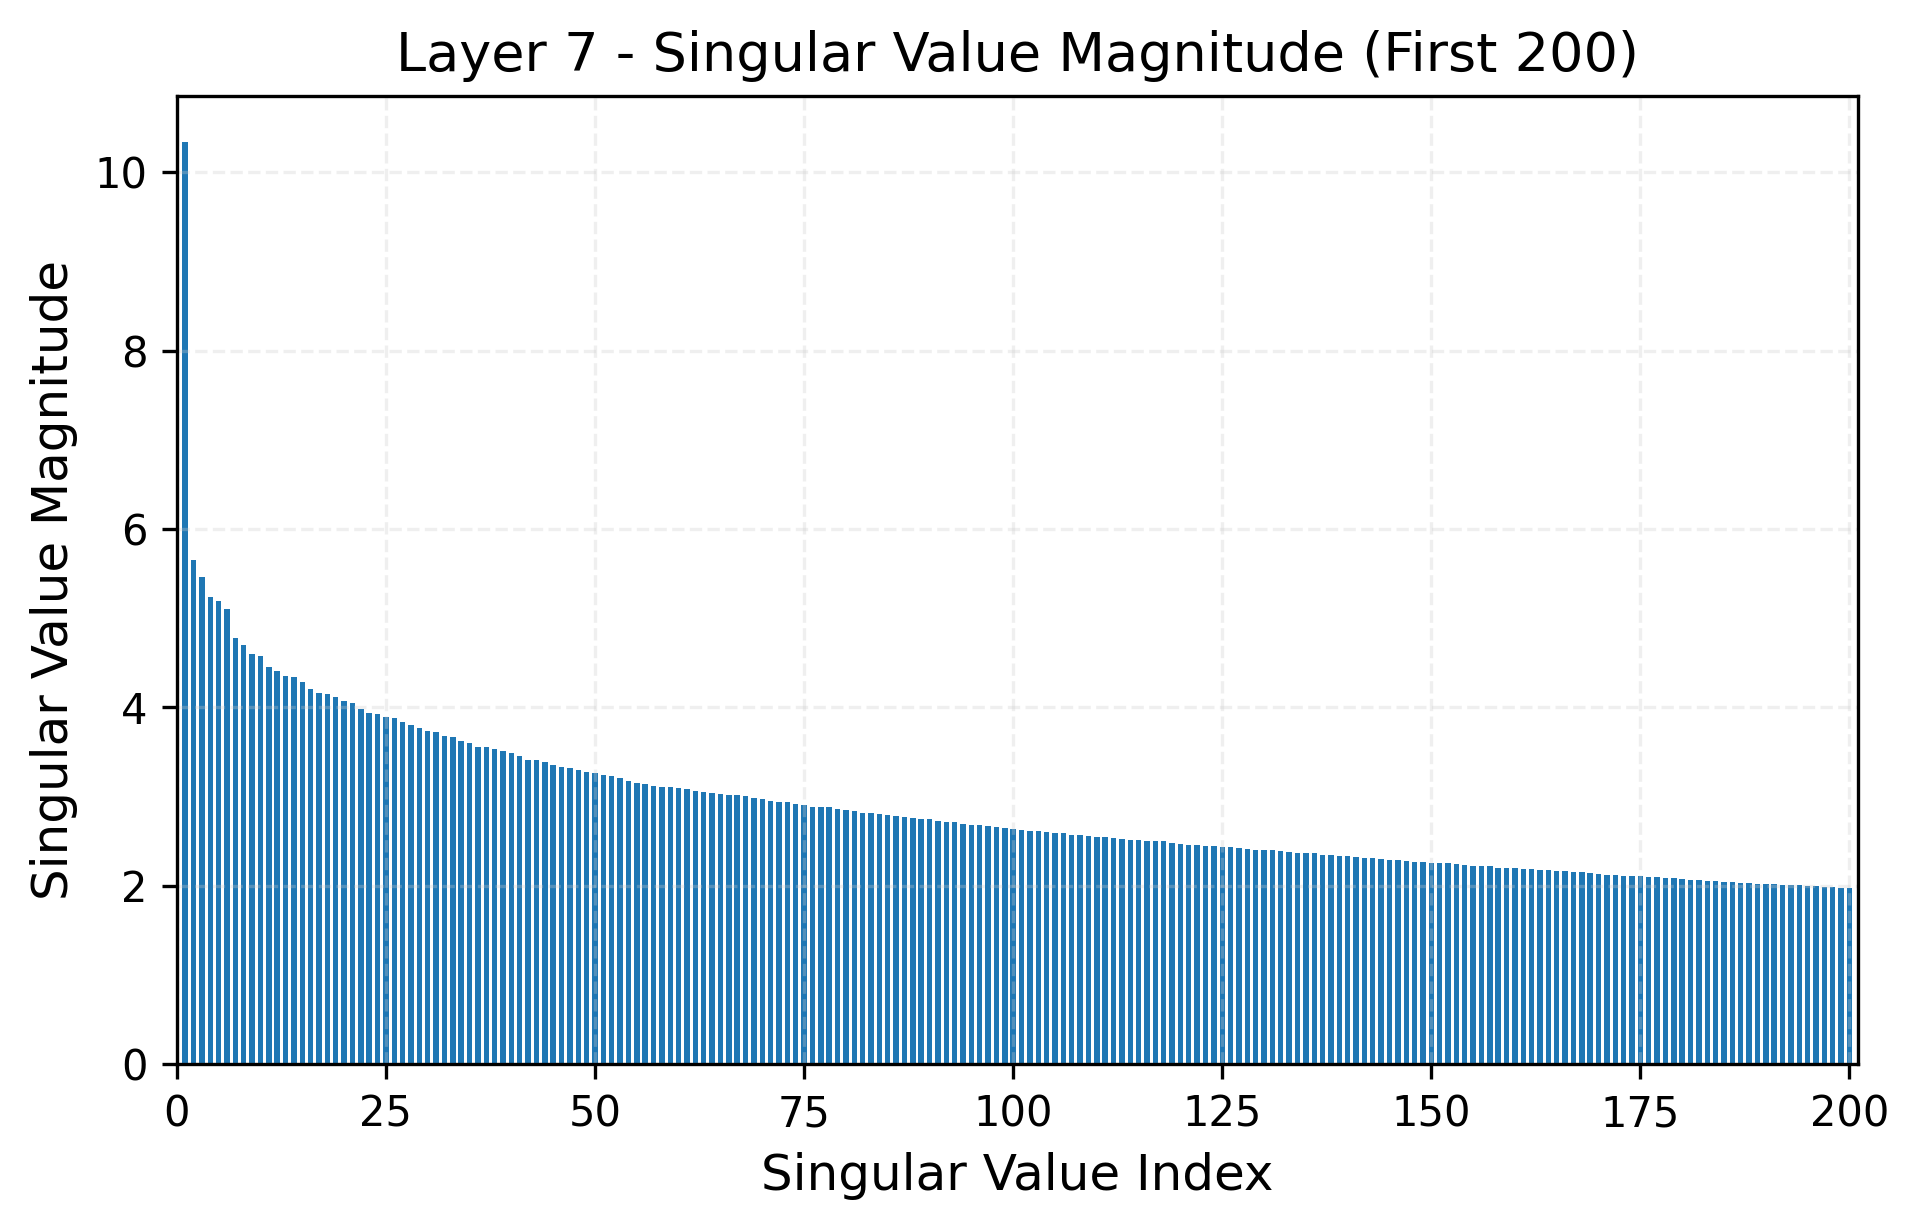

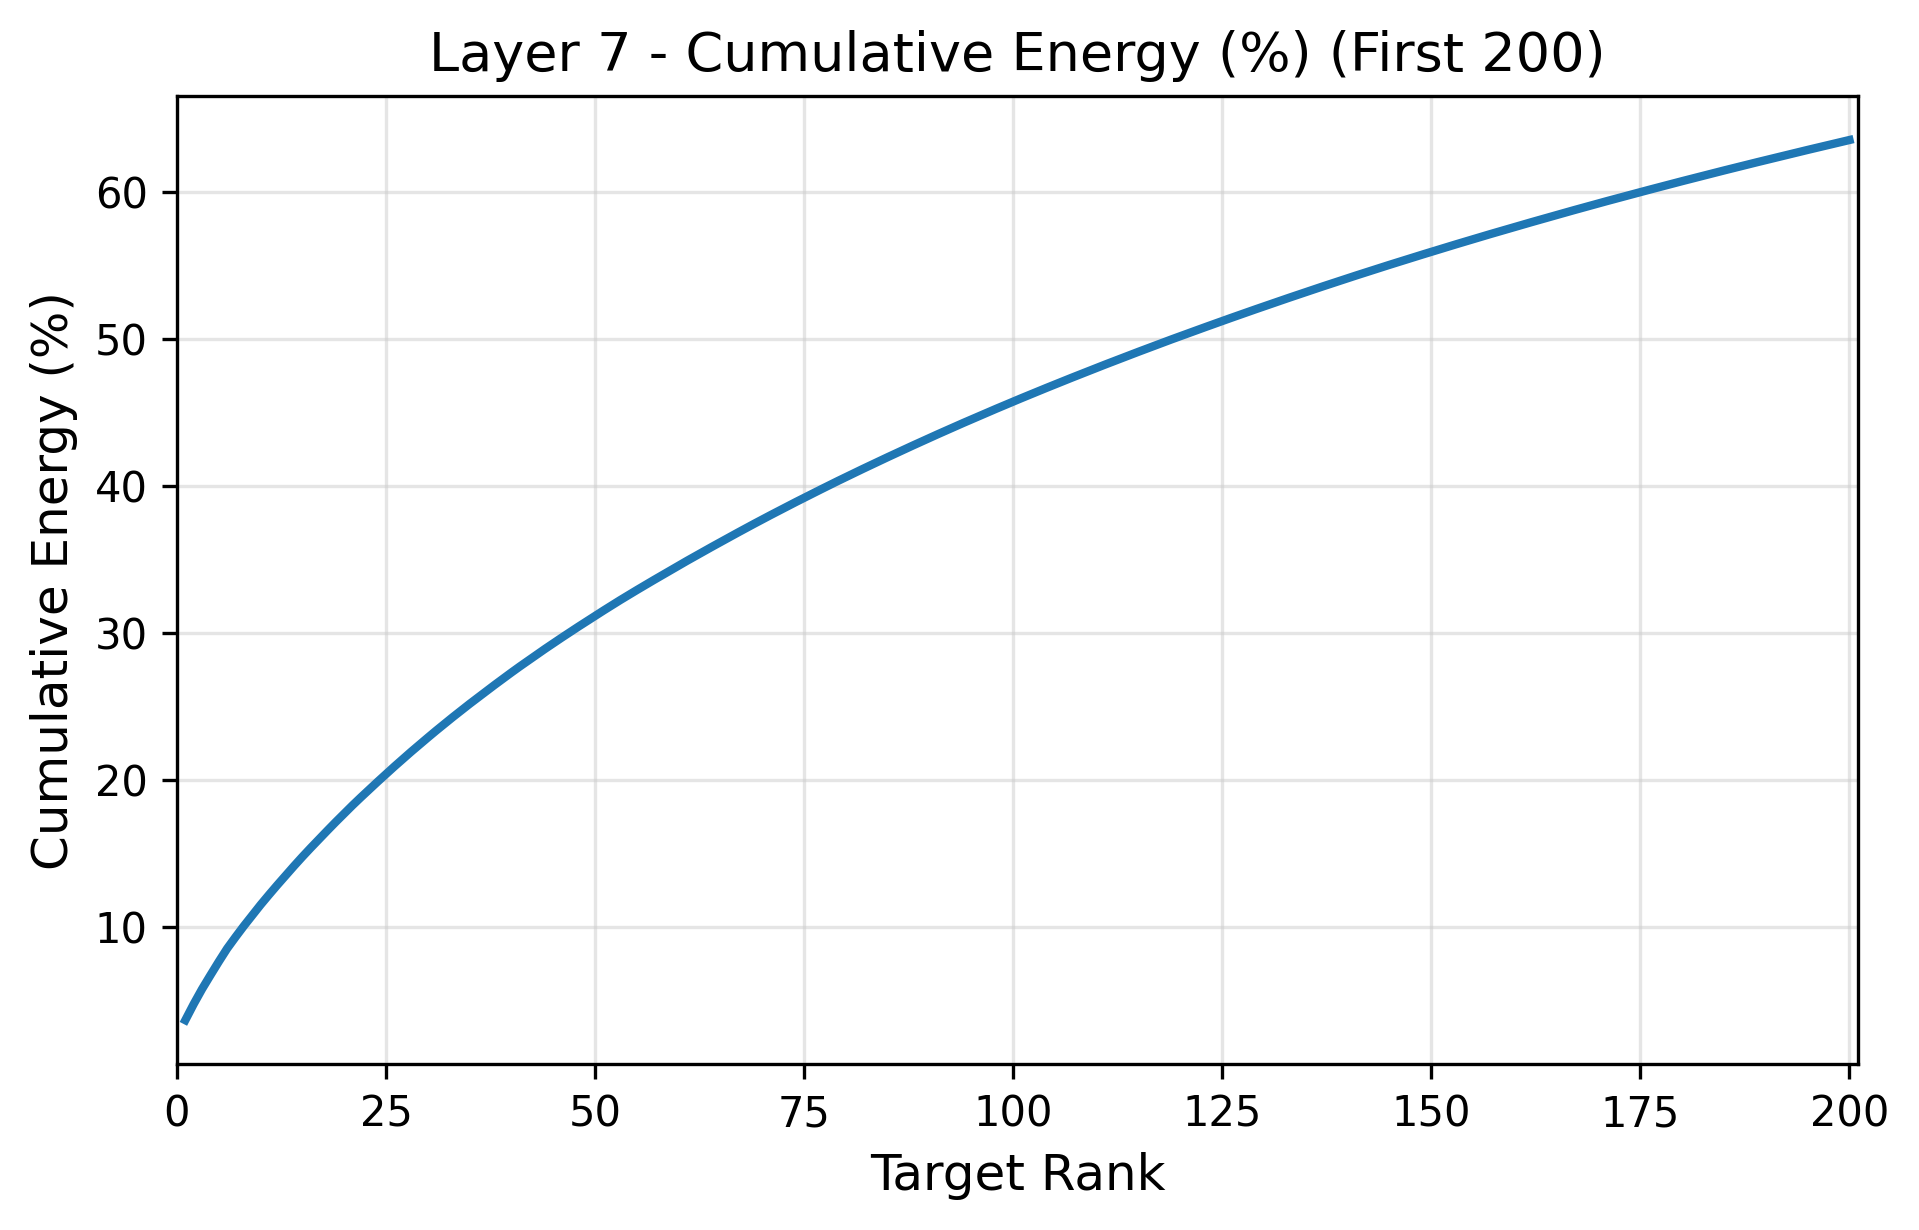

✅ Layer 7: 達到 50% 能量所需的 Minimum Target Rank = 120


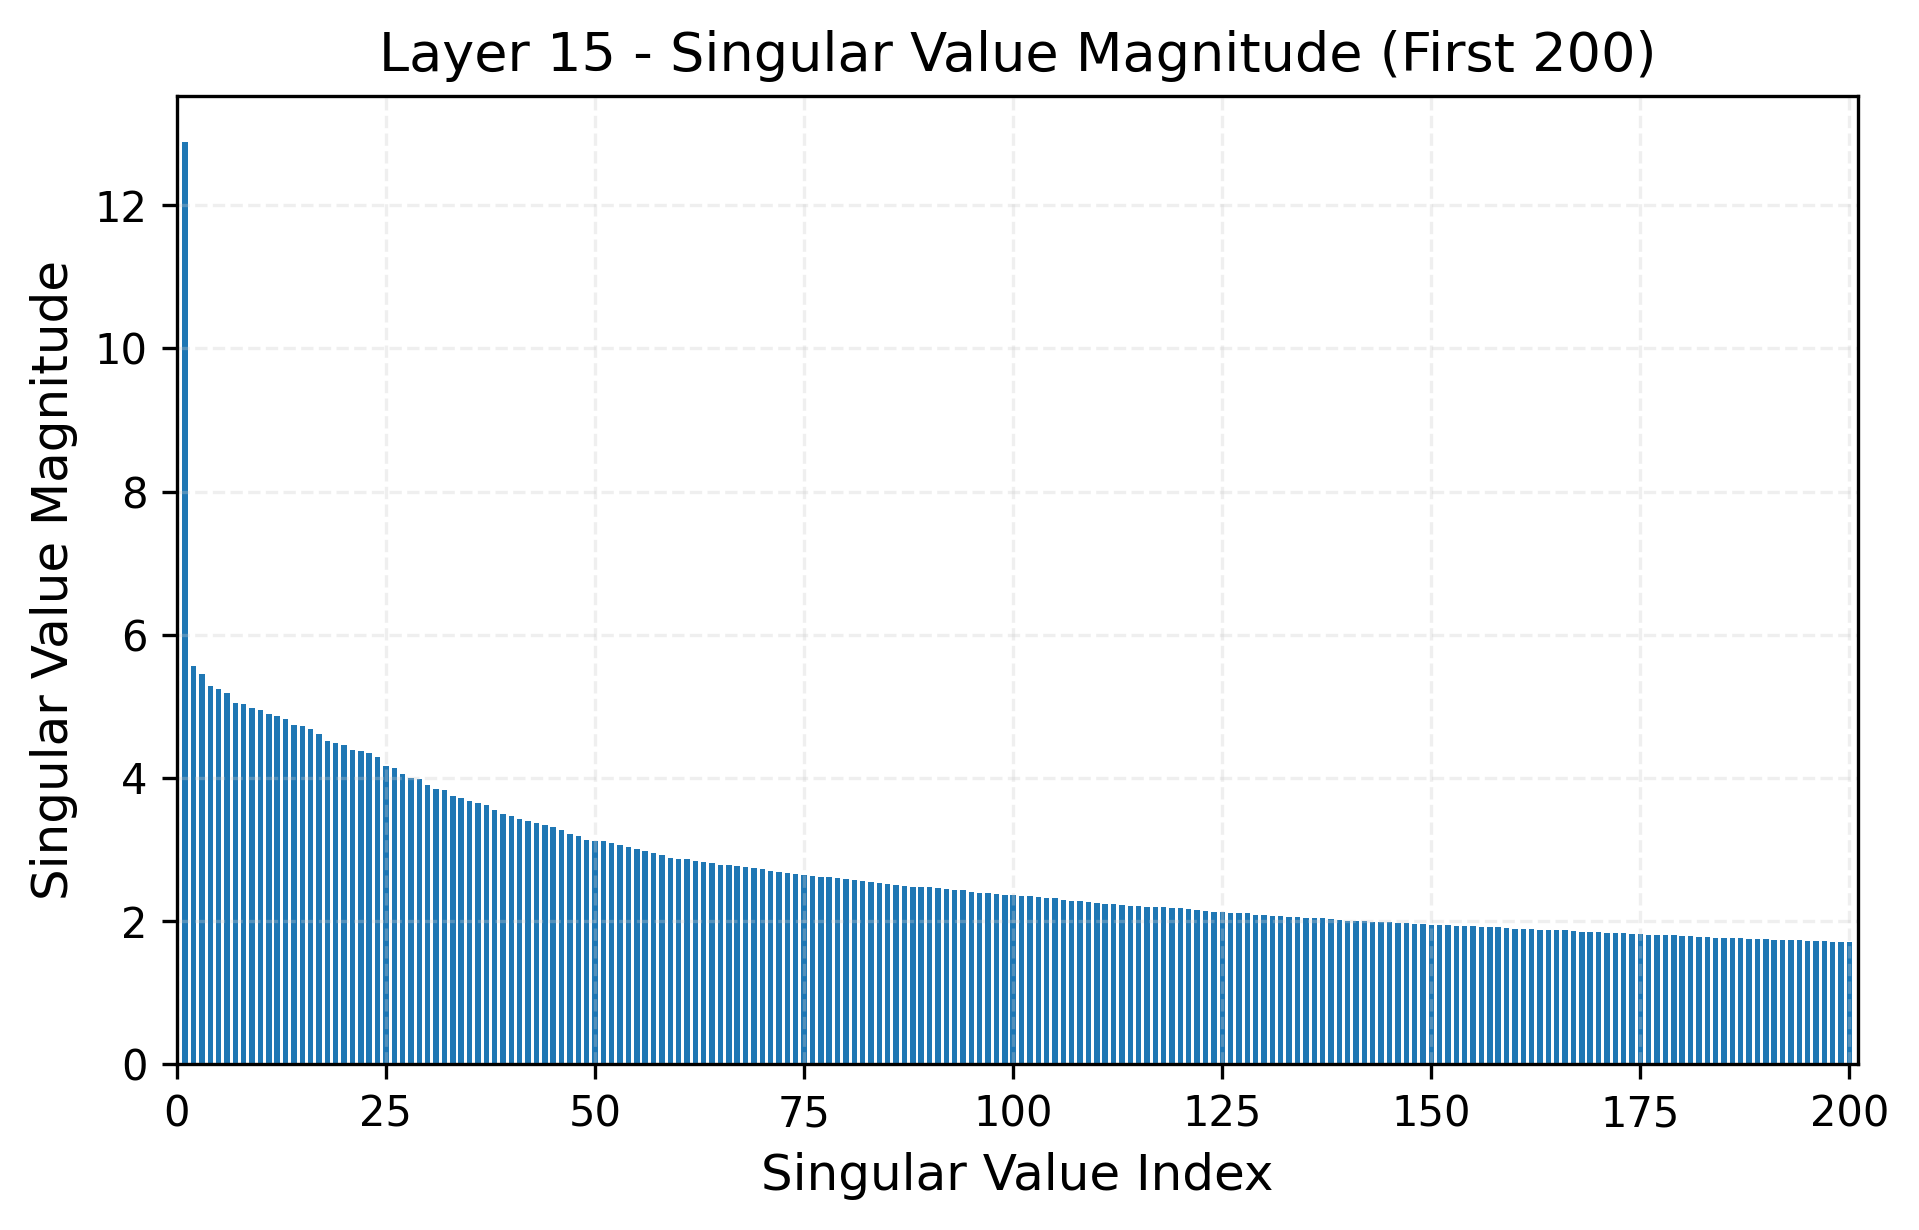

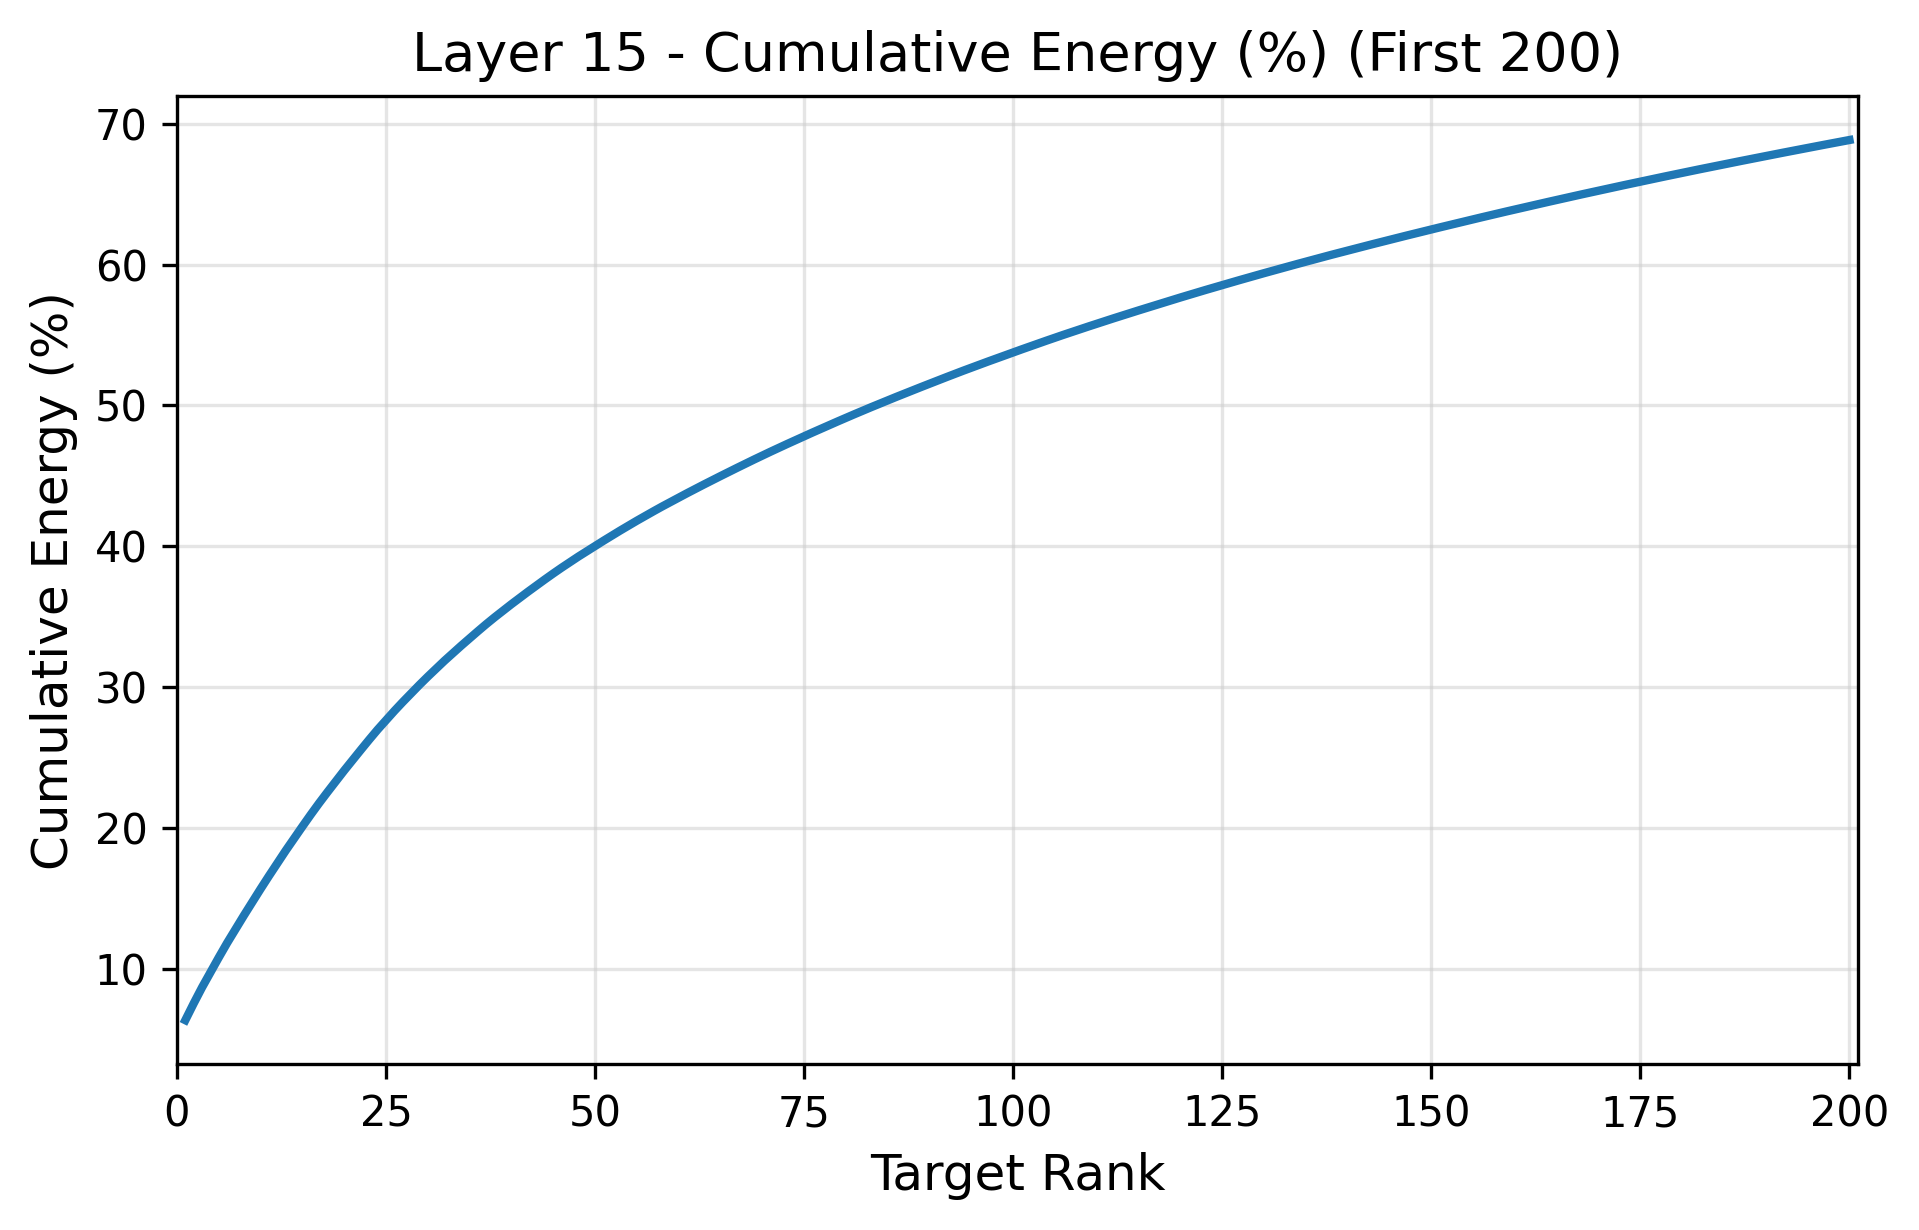

✅ Layer 15: 達到 50% 能量所需的 Minimum Target Rank = 84

📊 Question 4 Report Summary Table


,Layer 0,Layer 7,Layer 15
Minimum Target Rank for query projection weights,62,120,84



🎉 Q4 分析完成！共生成 6 張高清圖表與摘要表格，已存至: /kaggle/working/Assignment1


In [10]:
# TODO for Question 4
"""
Hint:
# Analyze the weights of the query projection layer (q_proj) where layer = k
 q_weight = model.model.layers[k].self_attn.q_proj.weight.detach()

# Apply SVD to decompose the weight matrix into U (left singular vectors), S (singular values), and V (right singular vectors).
 U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)

# Compute the retained energy ratio (Cumulative energy) of each singular value.
energy_ratio = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100
s"""
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from transformers import AutoModelForCausalLM

# 1. 設定儲存路徑
RESULT_ROOT = Path('/kaggle/working/Assignment1')
RESULT_ROOT.mkdir(parents=True, exist_ok=True)

layers_to_analyze = [0, 7, 15]
min_ranks_50 = {}

print("\n" + "="*70)
print("Question 4: SVD Analysis on q_proj Weights (Layers 0, 7, 15)")
print("="*70)

for layer_idx in layers_to_analyze:
    # A. 提取第 k 層 self_attn.q_proj 的權重矩陣
    q_weight = model.model.layers[layer_idx].self_attn.q_proj.weight.detach()
    
    # B. 進行 Full SVD 分解: W = U * S * Vh
    U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)
    
    # C. 計算累積能量比例 Cumulative Energy Ratio (%)
    energy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100
    
    # D. 尋找累積能量達到/超過 50% 的最小 Target Rank (+1 因為索引從 0 開始)
    rank_50 = (torch.searchsorted(energy_ratios, 50.0) + 1).item()
    min_ranks_50[f'Layer {layer_idx}'] = rank_50
    
    # 轉為 numpy array (依範例取前 200 個奇異值進行繪圖)
    S_top200 = S[:200].cpu().numpy()
    energy_top200 = energy_ratios[:200].cpu().numpy()
    indices = np.arange(1, 201)
    
    # -------------------------------------------------------------
    # 繪製圖一：Singular Value Magnitude (清晰的 Bar Chart)
    # -------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(6.5, 4.2), dpi=300)
    
    # 將 width 調小至 0.65，並加上邊框色或設不同顏色
    ax.bar(indices, S_top200, width=0.65, color='#1f77b4', align='center')
    
    ax.set_xlabel('Singular Value Index', fontsize=12)
    ax.set_ylabel('Singular Value Magnitude', fontsize=12)
    ax.set_title(f'Layer {layer_idx} - Singular Value Magnitude (First 200)', fontsize=13)
    ax.grid(True, linestyle='--', alpha=0.3, color='#cccccc')
    ax.set_xlim(0, 201)
    plt.tight_layout()
    
    bar_chart_path = RESULT_ROOT / f'q4_layer_{layer_idx}_sv_magnitude.png'
    plt.savefig(bar_chart_path, dpi=300)
    plt.show()
    plt.close()
    
    # -------------------------------------------------------------
    # 繪製圖二：Cumulative Energy (%) (Line Chart)
    # -------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(6.5, 4.2), dpi=300)
    ax.plot(indices, energy_top200, color='#1f77b4', linewidth=2.0)
    ax.set_xlabel('Target Rank', fontsize=12)
    ax.set_ylabel('Cumulative Energy (%)', fontsize=12)
    ax.set_title(f'Layer {layer_idx} - Cumulative Energy (%) (First 200)', fontsize=13)
    ax.grid(True, linestyle='-', alpha=0.5, color='#cccccc')
    ax.set_xlim(0, 201)
    plt.tight_layout()
    
    line_chart_path = RESULT_ROOT / f'q4_layer_{layer_idx}_cum_energy.png'
    plt.savefig(line_chart_path, dpi=300)
    plt.show()
    plt.close()
    
    print(f"✅ Layer {layer_idx}: 達到 50% 能量所需的 Minimum Target Rank = {rank_50}")

# 3. 輸出簡報所需規格的 Summary 表格
print("\n" + "="*70)
print("📊 Question 4 Report Summary Table")
print("="*70)

summary_data = {
    'Layer 0': [min_ranks_50['Layer 0']],
    'Layer 7': [min_ranks_50['Layer 7']],
    'Layer 15': [min_ranks_50['Layer 15']]
}

summary_df = pd.DataFrame(
    summary_data, 
    index=['Minimum Target Rank for query projection weights']
)

display(summary_df)

# 保存 CSV 備份
summary_df.to_csv(RESULT_ROOT / 'q4_minimum_target_ranks.csv')
print(f"\n🎉 Q4 分析完成！共生成 6 張高清圖表與摘要表格，已存至: {RESULT_ROOT}")